<a href="https://colab.research.google.com/github/rahulsapkota01/Rahul_INFO4670_Fall2026/blob/main/INFO4670_Week3_Assignment1_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — Making Sense of Northgate through Visualization
**INFO 4670 · Data Analysis and Knowledge Discovery**  ·  **Due: Sunday, 11:59 PM**

**Name:** Rahul Sapkota **Date:** 09/06/2026

**The situation.** The Provost's question stands: *which students are struggling, and can we see it earlier?* This week you answer it the way analysts do — not by reading rows, but by drawing the data. Every chart below is built by **adapting code from the Guided notebook**; the intellectual work is choosing the right chart and reading it honestly.

**For every chart you make, you must:**
1. **Choose** the chart type that fits the variable(s) and the question.
2. **Build** it in Colab from the Northgate files.
3. **Label** it fully — title, axis labels, and units/legend. *An unlabeled chart is an unfinished chart.*
4. **Write a STAR story** underneath it — Scope · Track · Articulate · Respond (defined on the Concepts deck).

**How to work:** run Setup and Load first. Then, for each question, copy the closest cell from the Guided notebook into the empty cell, adapt it, and fill in the STAR cell below it.

**Submit:** push this notebook to GitHub and submit the **GitHub link** in Canvas. (See the setup doc: *Colab_GitHub_Setup_INFO4670_Fall2026*.)

## Setup — run this first (you don't need to change it)

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Northgate house style (optional, but keeps your charts consistent)
NAVY = "#22303A"
RUST = "#C0562F"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]   = (8, 5)
plt.rcParams["axes.titlesize"]   = 13
plt.rcParams["axes.titleweight"] = "bold"

## Load the data — run this, then look before you plot

In [25]:
# STEP 1 — get the data into this notebook. Pick ONE option, then run.

DATA_DIR = "/"   # OPTION 2 (default) · drag the 3 CSVs into the file panel on the left

# OPTION 1 · read from Google Drive — uncomment and edit the path:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/.../Data"

import os
students = pd.read_csv(os.path.join(DATA_DIR, "student_records.csv"))
weekly   = pd.read_csv(os.path.join(DATA_DIR, "weekly_activity.csv"))
students.head()

,student_id,major,age,housing,commute_miles,work_hours_per_week,advisor_meetings,credits_attempted,final_gpa,study_hours_reported,enrollment_date,dropped_out
0,NU-101508,Data Science,27,Off-Campus,7.6,15,1,81,1.86,NaN,2023-09-13,1
1,NU-102438,Learning Technologies,25,With Family,14.3,35,1,100,2.06,9.5,2023-10-19,0
2,NU-102385,Learning Technologies,26,With Family,3.4,18,9,77,3.41,19.1,11/16/2022,0
3,NU-100767,Cyber Security,22,On-Campus,23.7,40,1,65,1.73,8.1,2024-05-03,0
4,NU-106054,Information Technology,21,Off-Campus,2.3,20,4,59,2.37,6.6,10/24/2022,0


In [26]:
# how many rows, which columns, what types?
students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2027 entries, 0 to 2026
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            2027 non-null   object 
 1   major                 2027 non-null   object 
 2   age                   2027 non-null   int64  
 3   housing               2027 non-null   object 
 4   commute_miles         2027 non-null   float64
 5   work_hours_per_week   2027 non-null   int64  
 6   advisor_meetings      2027 non-null   int64  
 7   credits_attempted     2027 non-null   int64  
 8   final_gpa             2027 non-null   float64
 9   study_hours_reported  1772 non-null   float64
 10  enrollment_date       2027 non-null   object 
 11  dropped_out           2027 non-null   int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 190.2+ KB


In [27]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Part A — Guided questions
Build **one chart per question**. Each maps to one chart family from this week. Copy the closest Guided-notebook cell, adapt it, label it, then write its STAR story.

### Q1 · One quantitative variable
**How many hours per week do Northgate students work?** Describe what's typical, how spread out it is, and whether anyone stands apart.
→ *histogram* (add a *box plot* if it helps). Column: `work_hours_per_week` (from `students`).

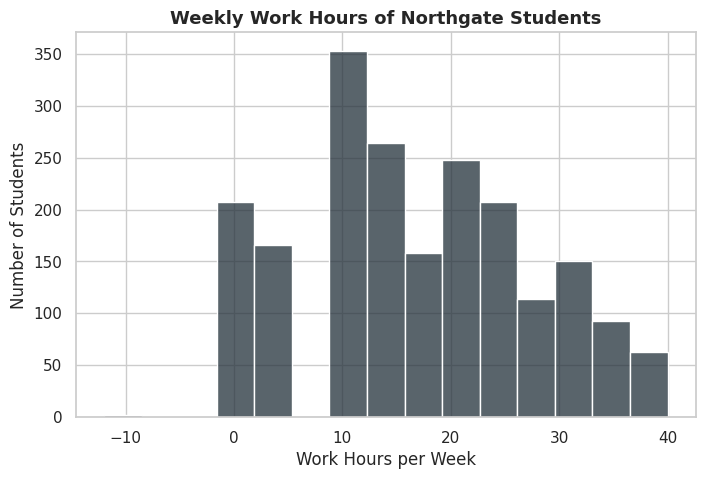

In [28]:
fig, ax = plt.subplots()

sns.histplot(data=students, x="work_hours_per_week", bins=15, color=NAVY, ax=ax)

ax.set_title("Weekly Work Hours of Northgate Students")
ax.set_xlabel("Work Hours per Week")
ax.set_ylabel("Number of Students")

plt.show()


**STAR story — Q1** *(write in your own words)*

- **Scope —** This chart shows the work hours per week for Northgate students.
- **Track —** It shows how many hours students usually work each week and how the work hours are spread out.
- **Articulate —** Most students work between about 10 and 30 hours per week, with many students around 10–15 hours.
- **Respond —** Some values are below 0 hours, which is not realistic. I would check these records for possible data errors before doing further analysis.


### Q2 · One categorical variable
**How does enrollment compare across majors?**
→ *sorted bar chart*. Column: `major` (from `students`).

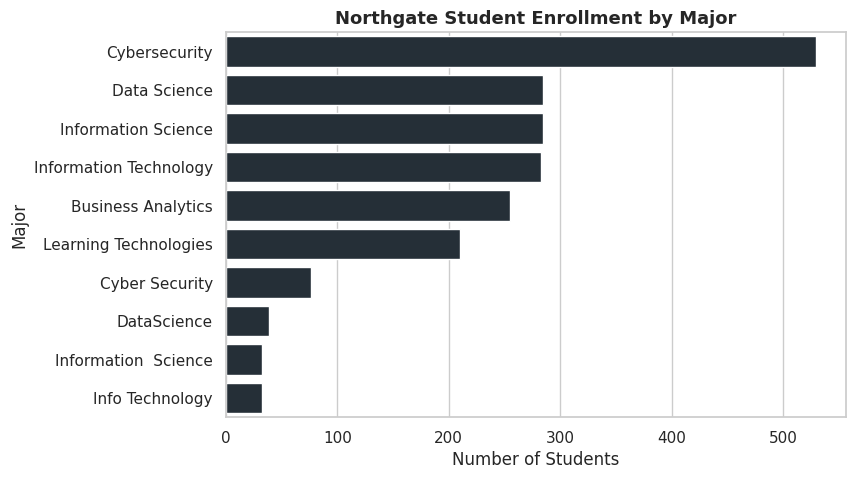

In [29]:
major_counts = students["major"].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots()

sns.barplot(x=major_counts.values, y=major_counts.index, color=NAVY, ax=ax)

ax.set_title("Northgate Student Enrollment by Major")
ax.set_xlabel("Number of Students")
ax.set_ylabel("Major")

plt.show()


**STAR story — Q2** *(write in your own words)*

- **Scope —** This chart shows the number of Northgate students in each major.
- **Track —** It compares student enrollment across the different majors.
- **Articulate —**Cybersecurity has the highest enrollment with more than 500 students. Data Science, Information Science, and Information Technology each have around 280 students.
- **Respond —** Some major names appear more than once with different spelling or formatting, such as Cybersecurity and Cyber Security. I would check and standardize these names before further analysis.

### Q3 · A quantity, split by category
**Does final GPA differ across majors?** Read the exceptions, not just the boxes.
→ *box plot per major*. Columns: `final_gpa` and `major` (from `students`).

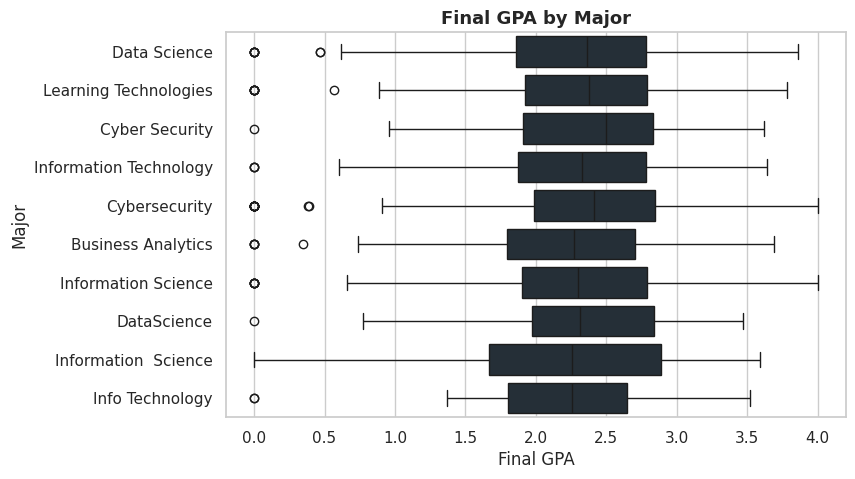

In [30]:
fig, ax = plt.subplots()

sns.boxplot(data=students, x="final_gpa", y="major", color=NAVY, ax=ax)

ax.set_title("Final GPA by Major")
ax.set_xlabel("Final GPA")
ax.set_ylabel("Major")

plt.show()


**STAR story — Q3** *(write in your own words)*

- **Scope —** This chart shows the final GPA of Northgate students grouped by major.
- **Track —** It compares the typical GPA and spread of GPA across different majors.
- **Articulate —** Final GPA is fairly similar across most majors, with median GPAs around 2.3 to 2.6. Some majors have a wider spread than others.
- **Respond —** There are several unusually low GPA values near 0, and some major names have inconsistent formatting. I would check these records and major names before further analysis.

### Q4 · Two quantitative variables
**Is there a relationship between how far students commute and their final GPA?** Remember: *association is not causation.*
→ *scatterplot with a trend line*. Columns: `commute_miles` and `final_gpa` (from `students`).

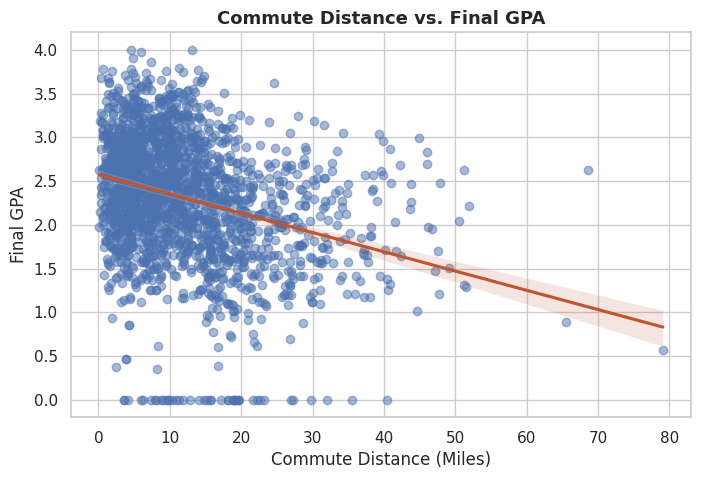

In [31]:
fig, ax = plt.subplots()

sns.regplot(
    data=students,
    x="commute_miles",
    y="final_gpa",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": RUST},
    ax=ax
)

ax.set_title("Commute Distance vs. Final GPA")
ax.set_xlabel("Commute Distance (Miles)")
ax.set_ylabel("Final GPA")

plt.show()


**STAR story — Q4** *(write in your own words)*

- **Scope — This chart shows the relationship between commute distance and final GPA for Northgate students.
- **Track —It looks at whether students who commute farther tend to have different final GPAs.
- **Articulate —The trend line slopes downward, showing that students with longer commutes tend to have lower final GPAs.
- **Respond — There are some unusual values, including several GPAs near 0 and a few very long commutes. I would check these records and other factors before making conclusions because association does not mean causation.

### Q5 · Over time
**How does student engagement change across the semester?**
→ *line chart* of average weekly activity. Use the `weekly` table: `week` and `minutes_active` (you'll need to average by week first — see the Guided notebook).

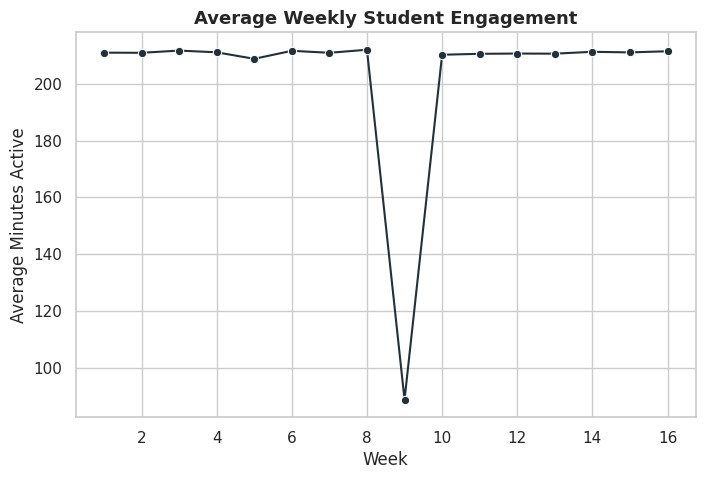

In [32]:
weekly_avg = weekly.groupby("week", as_index=False)["minutes_active"].mean()

fig, ax = plt.subplots()

sns.lineplot(
    data=weekly_avg,
    x="week",
    y="minutes_active",
    marker="o",
    color=NAVY,
    ax=ax
)

ax.set_title("Average Weekly Student Engagement")
ax.set_xlabel("Week")
ax.set_ylabel("Average Minutes Active")

plt.show()


**STAR story — Q5** *(write in your own words)*

- **Scope —** This chart shows the average weekly minutes active for Northgate students across the semester.
- **Track —** It shows how student engagement changes from week to week.
- **Articulate —** Average activity stays fairly steady at about 210 minutes for most weeks. However, there is a large drop in Week 9 to about 90 minutes before returning to normal in Week 10.
- **Respond —** Week 9 is unusual compared with all other weeks. I would check the Week 9 data to see if there was a data issue or another reason for the large drop.

# Part B — Your own question (open)
Pose **one question of your own** about the Northgate students, choose the chart that answers it, build it, label it, and write its STAR story. Going beyond Part A is rewarded — a per-student line chart, a violin plot, or a chart of a messier column are all fair game.

**Your question:** \_\_\_\_\_\_\_\_



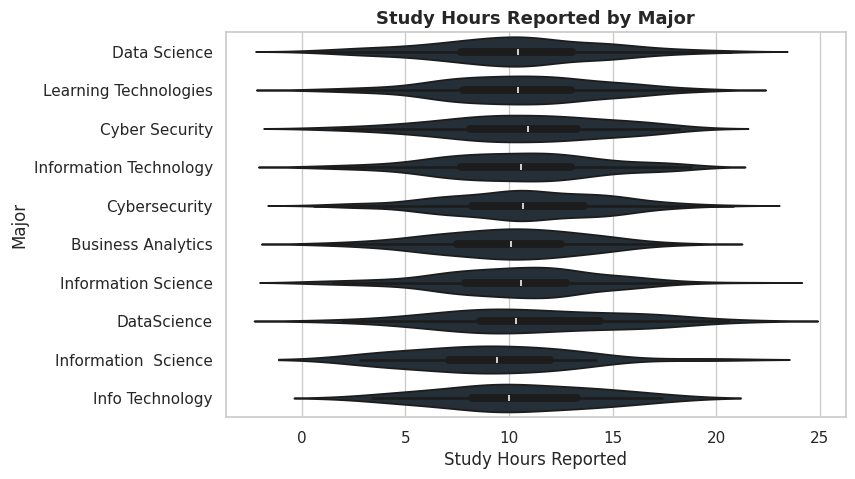

In [33]:
fig, ax = plt.subplots()

sns.violinplot(
    data=students,
    x="study_hours_reported",
    y="major",
    color=NAVY,
    ax=ax
)

ax.set_title("Study Hours Reported by Major")
ax.set_xlabel("Study Hours Reported")
ax.set_ylabel("Major")

plt.show()


**STAR story — Part B** *(write in your own words)*

- **Scope —** This chart shows reported study hours for Northgate students grouped by major.
- **Track —** It compares how study hours are distributed across different majors.
- **Articulate —** Study hours are fairly similar across most majors, with many students reporting around 10 to 11 hours. The distributions have some differences in their spread.
- **Respond —** Some reported study hours appear below 0, which is not realistic. I would check these records for possible data errors before further analysis.

# Before you submit — checklist
- [ ] The notebook **runs top to bottom** with no errors (Runtime → Restart and run all).
- [ ] All **6 charts** are present, each with a title, labeled axes, and units/legend where needed.
- [ ] Each chart has a **complete STAR story**, including any exceptions you spotted.
- [ ] Part B question is written in and answered.
- [ ] Pushed to **GitHub**, and the **GitHub link** is submitted in Canvas.

**Rubric (70 pts):** chart choice 10 · correct build 20 · labeling 10 · STAR reading 18 · Part B question 4 · submission & professionalism 8.